In [1]:
# Run this at the top of your notebook on a T4 GPU runtime
#%load_ext cuml.accel
#import sklearn

# Your standard Scikit-Learn Pipeline and GridSearchCV now run on GPU

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import kagglehub


In [3]:
kagglehub.login()

Kaggle credentials set.
Kaggle credentials successfully validated.


In [6]:
path = kagglehub.competition_download("rossmann-store-sales")

In [7]:
os.listdir(path)

['sample_submission.csv', 'store.csv', 'test.csv', 'train.csv']

In [8]:
ross_train = pd.read_csv(path +"/train.csv",low_memory=False)
ross_store = pd.read_csv(path + "/store.csv",low_memory=False)

In [9]:
#print(ross_train.info())
#print(ross_train.DayOfWeek.value_counts())
ross_train

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1
...,...,...,...,...,...,...,...,...,...
1017204,1111,2,2013-01-01,0,0,0,0,a,1
1017205,1112,2,2013-01-01,0,0,0,0,a,1
1017206,1113,2,2013-01-01,0,0,0,0,a,1
1017207,1114,2,2013-01-01,0,0,0,0,a,1


In [10]:
ross_store

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
1110,1111,a,a,1900.0,6.0,2014.0,1,31.0,2013.0,"Jan,Apr,Jul,Oct"
1111,1112,c,c,1880.0,4.0,2006.0,0,NaN,NaN,NaN
1112,1113,a,c,9260.0,NaN,NaN,0,NaN,NaN,NaN
1113,1114,a,c,870.0,NaN,NaN,0,NaN,NaN,NaN


# Merge Store and Train

In [11]:
merged_df=pd.merge(ross_train,ross_store,how="left",on="Store")

In [12]:
merged_train_df=merged_df.copy()

In [13]:
ross_test=pd.read_csv(path + "/test.csv",low_memory=False)

In [14]:
ross_test

,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday
0,1,1,4,2015-09-17,1.0,1,0,0
1,2,3,4,2015-09-17,1.0,1,0,0
2,3,7,4,2015-09-17,1.0,1,0,0
3,4,8,4,2015-09-17,1.0,1,0,0
4,5,9,4,2015-09-17,1.0,1,0,0
...,...,...,...,...,...,...,...,...
41083,41084,1111,6,2015-08-01,1.0,0,0,0
41084,41085,1112,6,2015-08-01,1.0,0,0,0
41085,41086,1113,6,2015-08-01,1.0,0,0,0
41086,41087,1114,6,2015-08-01,1.0,0,0,0


The test data did not include sales and customers

In [15]:
ross_train.columns

Index(['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo',
       'StateHoliday', 'SchoolHoliday'],
      dtype='object')

In [16]:
ross_train.Store.nunique()

1115

In [17]:
ross_store

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
1110,1111,a,a,1900.0,6.0,2014.0,1,31.0,2013.0,"Jan,Apr,Jul,Oct"
1111,1112,c,c,1880.0,4.0,2006.0,0,NaN,NaN,NaN
1112,1113,a,c,9260.0,NaN,NaN,0,NaN,NaN,NaN
1113,1114,a,c,870.0,NaN,NaN,0,NaN,NaN,NaN


In [18]:
merged_test=pd.merge(ross_test ,ross_store,how="left",on="Store")

In [19]:
merged_test_df=merged_test.copy()

In [20]:
merged_test_df

,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,1,4,2015-09-17,1.0,1,0,0,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,3,4,2015-09-17,1.0,1,0,0,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
2,3,7,4,2015-09-17,1.0,1,0,0,a,c,24000.0,4.0,2013.0,0,NaN,NaN,NaN
3,4,8,4,2015-09-17,1.0,1,0,0,a,a,7520.0,10.0,2014.0,0,NaN,NaN,NaN
4,5,9,4,2015-09-17,1.0,1,0,0,a,c,2030.0,8.0,2000.0,0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41083,41084,1111,6,2015-08-01,1.0,0,0,0,a,a,1900.0,6.0,2014.0,1,31.0,2013.0,"Jan,Apr,Jul,Oct"
41084,41085,1112,6,2015-08-01,1.0,0,0,0,c,c,1880.0,4.0,2006.0,0,NaN,NaN,NaN
41085,41086,1113,6,2015-08-01,1.0,0,0,0,a,c,9260.0,NaN,NaN,0,NaN,NaN,NaN
41086,41087,1114,6,2015-08-01,1.0,0,0,0,a,c,870.0,NaN,NaN,0,NaN,NaN,NaN


In [21]:
merged_test_df.columns=[col.lower() for col in merged_test_df.columns ]
merged_test_df.columns

Index(['id', 'store', 'dayofweek', 'date', 'open', 'promo', 'stateholiday',
       'schoolholiday', 'storetype', 'assortment', 'competitiondistance',
       'competitionopensincemonth', 'competitionopensinceyear', 'promo2',
       'promo2sinceweek', 'promo2sinceyear', 'promointerval'],
      dtype='object')

In [22]:
merged_train_df.columns=[col.lower() for col in merged_train_df.columns ]

# Data cleaning

In [23]:
merged_train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 18 columns):
 #   Column                     Non-Null Count    Dtype  
---  ------                     --------------    -----  
 0   store                      1017209 non-null  int64  
 1   dayofweek                  1017209 non-null  int64  
 2   date                       1017209 non-null  object 
 3   sales                      1017209 non-null  int64  
 4   customers                  1017209 non-null  int64  
 5   open                       1017209 non-null  int64  
 6   promo                      1017209 non-null  int64  
 7   stateholiday               1017209 non-null  object 
 8   schoolholiday              1017209 non-null  int64  
 9   storetype                  1017209 non-null  object 
 10  assortment                 1017209 non-null  object 
 11  competitiondistance        1014567 non-null  float64
 12  competitionopensincemonth  693861 non-null   float64
 13  competitiono

In [24]:
round(merged_train_df.describe().T,2)

,count,mean,std,min,25%,50%,75%,max
store,1017209.0,558.43,321.91,1.0,280.0,558.0,838.0,1115.0
dayofweek,1017209.0,4.00,2.00,1.0,2.0,4.0,6.0,7.0
sales,1017209.0,5773.82,3849.93,0.0,3727.0,5744.0,7856.0,41551.0
customers,1017209.0,633.15,464.41,0.0,405.0,609.0,837.0,7388.0
open,1017209.0,0.83,0.38,0.0,1.0,1.0,1.0,1.0
promo,1017209.0,0.38,0.49,0.0,0.0,0.0,1.0,1.0
schoolholiday,1017209.0,0.18,0.38,0.0,0.0,0.0,0.0,1.0
competitiondistance,1014567.0,5430.09,7715.32,20.0,710.0,2330.0,6890.0,75860.0
competitionopensincemonth,693861.0,7.22,3.21,1.0,4.0,8.0,10.0,12.0
competitionopensinceyear,693861.0,2008.69,5.99,1900.0,2006.0,2010.0,2013.0,2015.0


In [25]:
merged_train_df.duplicated().sum()

np.int64(0)

In [26]:
merged_train_df.date=pd.to_datetime(merged_train_df.date)

In [27]:
merged_test_df.date=pd.to_datetime(merged_test_df.date)

In [28]:
merged_train_df["date"].min(),merged_train_df["date"].max()

(Timestamp('2013-01-01 00:00:00'), Timestamp('2015-07-31 00:00:00'))

In [29]:
merged_test_df["date"].min(),merged_test_df["date"].max()

(Timestamp('2015-08-01 00:00:00'), Timestamp('2015-09-17 00:00:00'))

# Exploratory Data Analysis and Visualization

<Axes: xlabel='sales', ylabel='Count'>

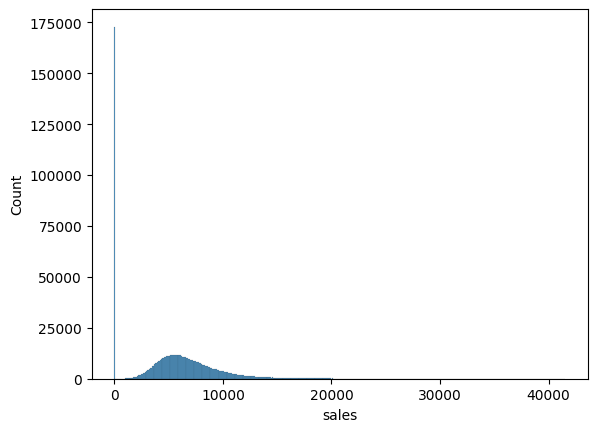

In [30]:
sns.histplot(data=merged_train_df,x="sales")

In [31]:
merged_train_df

,store,dayofweek,date,sales,customers,open,promo,stateholiday,schoolholiday,storetype,assortment,competitiondistance,competitionopensincemonth,competitionopensinceyear,promo2,promo2sinceweek,promo2sinceyear,promointerval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1017204,1111,2,2013-01-01,0,0,0,0,a,1,a,a,1900.0,6.0,2014.0,1,31.0,2013.0,"Jan,Apr,Jul,Oct"
1017205,1112,2,2013-01-01,0,0,0,0,a,1,c,c,1880.0,4.0,2006.0,0,NaN,NaN,NaN
1017206,1113,2,2013-01-01,0,0,0,0,a,1,a,c,9260.0,NaN,NaN,0,NaN,NaN,NaN
1017207,1114,2,2013-01-01,0,0,0,0,a,1,a,c,870.0,NaN,NaN,0,NaN,NaN,NaN


In [32]:
merged_train_df["open"].value_counts()

,count
open,
1,844392
0,172817


In [33]:
merged_train_df["sales"].value_counts()[0]

np.int64(172871)

In [34]:
merged_train_df=merged_train_df[merged_train_df["open"]==1].copy()

In [35]:
merged_train_df

,store,dayofweek,date,sales,customers,open,promo,stateholiday,schoolholiday,storetype,assortment,competitiondistance,competitionopensincemonth,competitionopensinceyear,promo2,promo2sinceweek,promo2sinceyear,promointerval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1016776,682,2,2013-01-01,3375,566,1,0,a,1,b,a,150.0,9.0,2006.0,0,NaN,NaN,NaN
1016827,733,2,2013-01-01,10765,2377,1,0,a,1,b,b,860.0,10.0,1999.0,0,NaN,NaN,NaN
1016863,769,2,2013-01-01,5035,1248,1,0,a,1,b,b,840.0,NaN,NaN,1,48.0,2012.0,"Jan,Apr,Jul,Oct"
1017042,948,2,2013-01-01,4491,1039,1,0,a,1,b,b,1430.0,NaN,NaN,0,NaN,NaN,NaN


<Axes: xlabel='sales', ylabel='Count'>

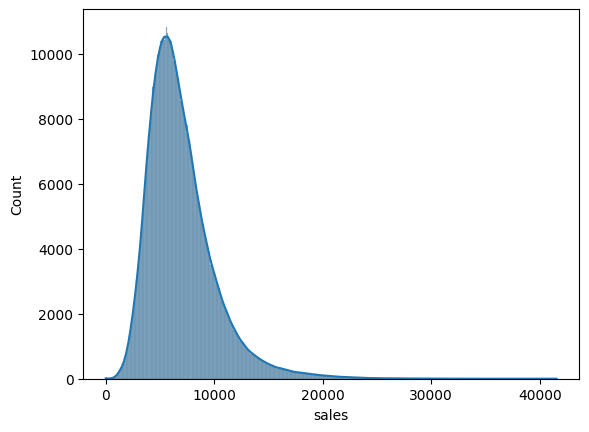

In [36]:
sns.histplot(data=merged_train_df,x="sales",kde=True)

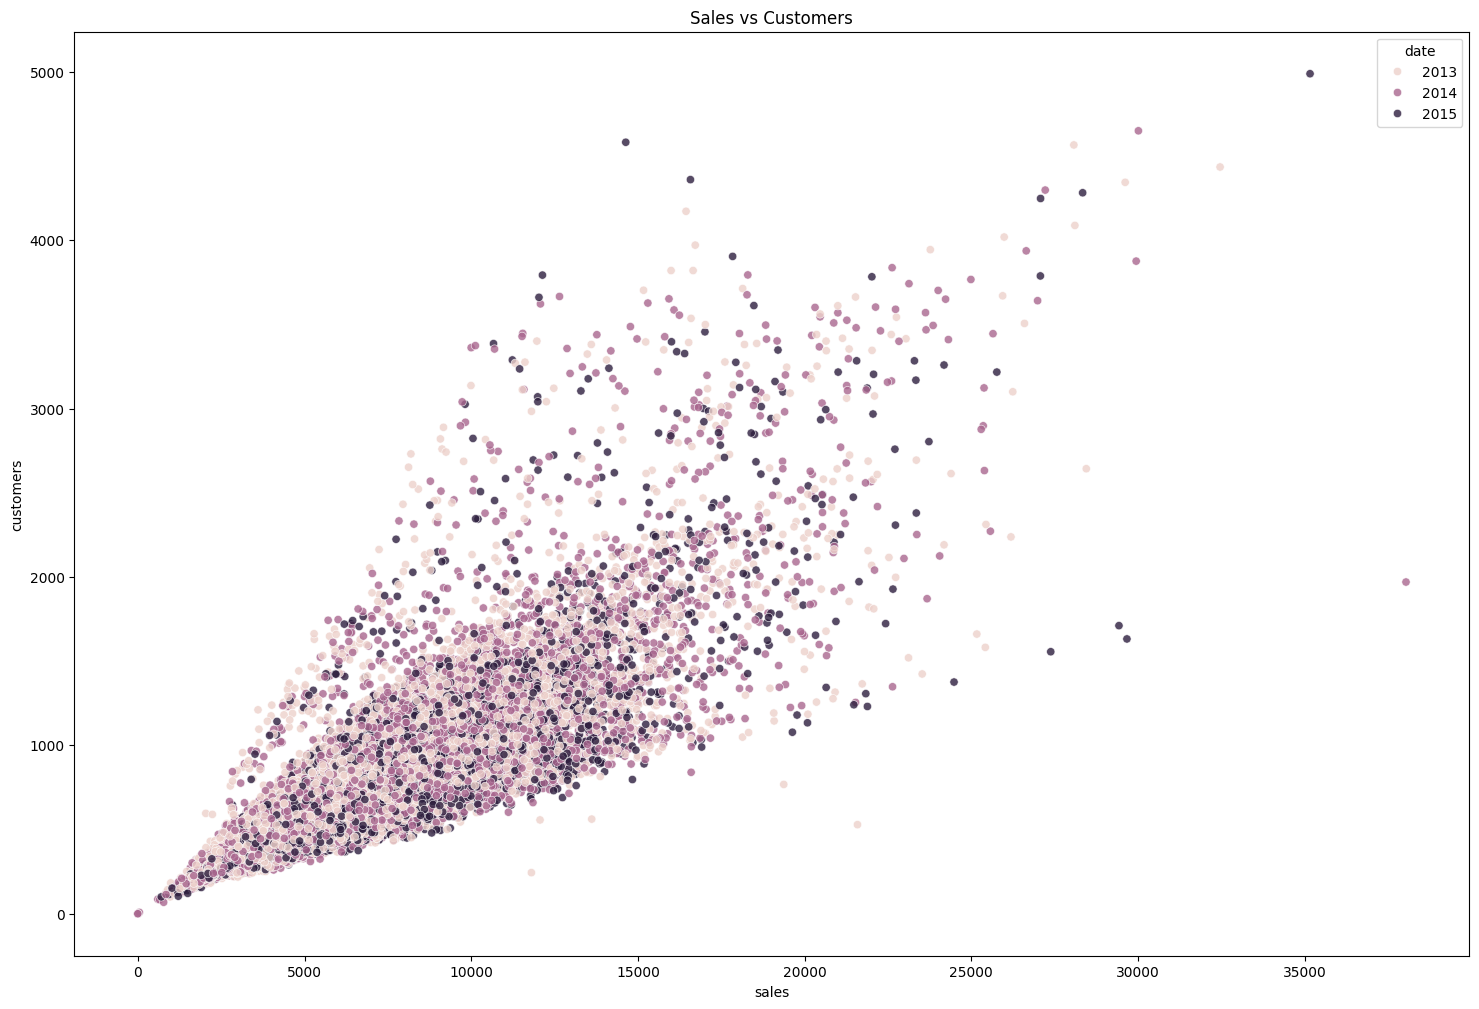

In [37]:
plt.figure(figsize=(18,12))
temp_df = merged_train_df.sample(40000)
sns.scatterplot(x="sales",y="customers",data=temp_df,hue=temp_df.date.dt.year,alpha=0.8)
plt.title("Sales vs Customers")
plt.show()
#

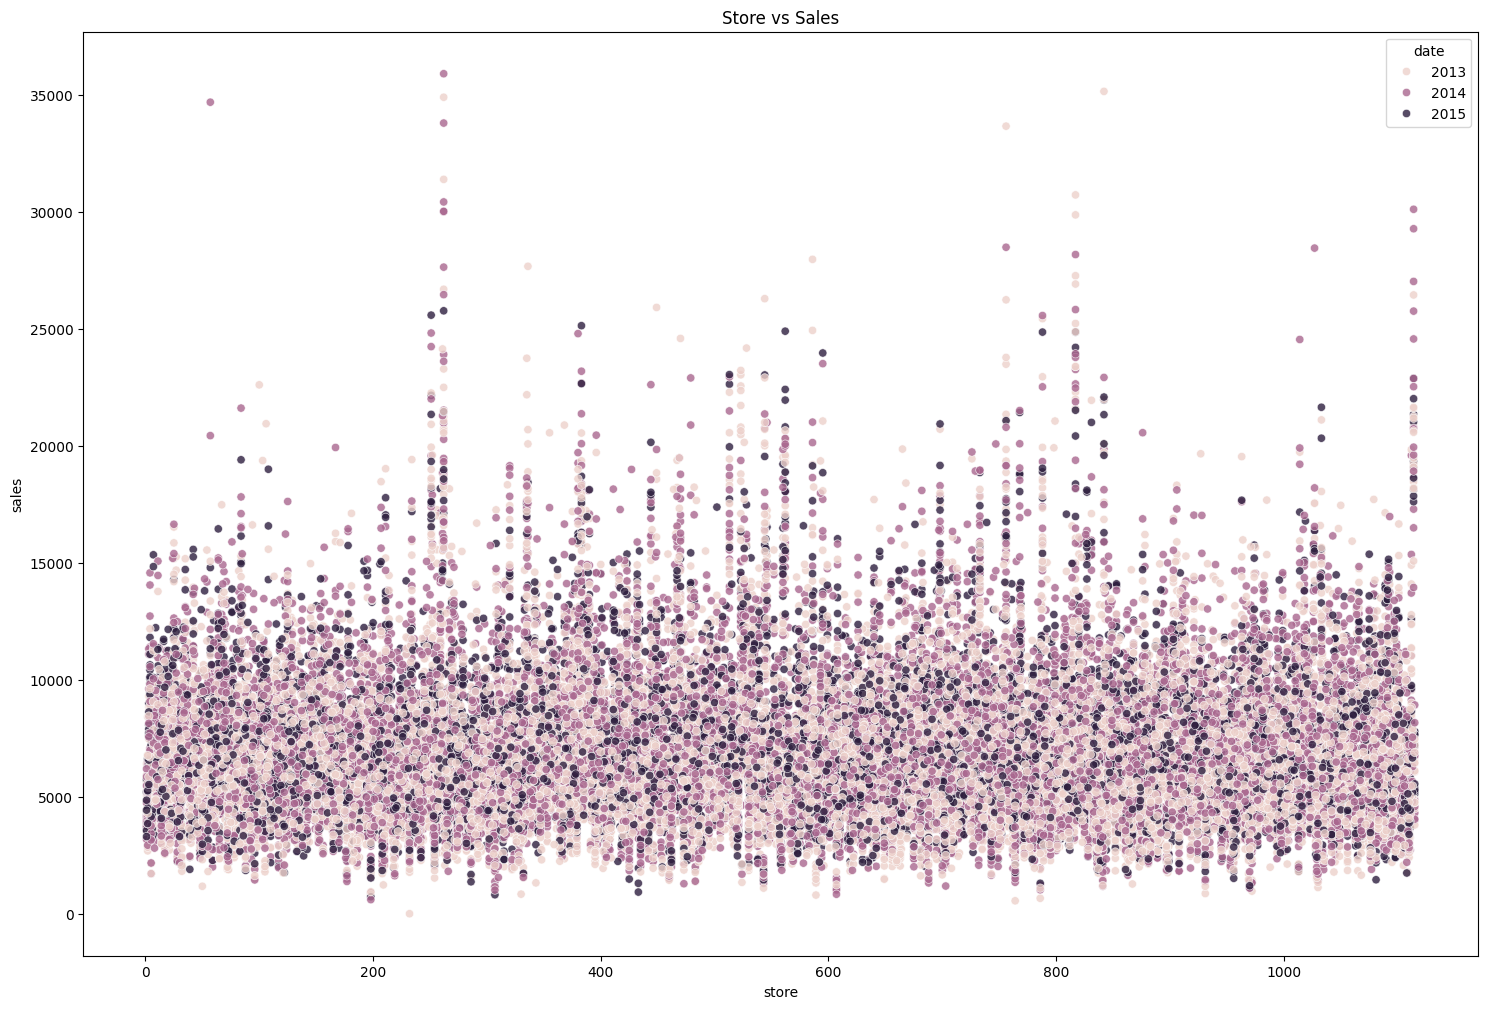

In [38]:
plt.figure(figsize=(18,12))
temp_df = merged_train_df.sample(40000)
sns.scatterplot(x="store",y="sales",data=temp_df,hue=temp_df.date.dt.year,alpha=0.8)
plt.title("Store vs Sales")
plt.show()


<Axes: xlabel='dayofweek', ylabel='sales'>

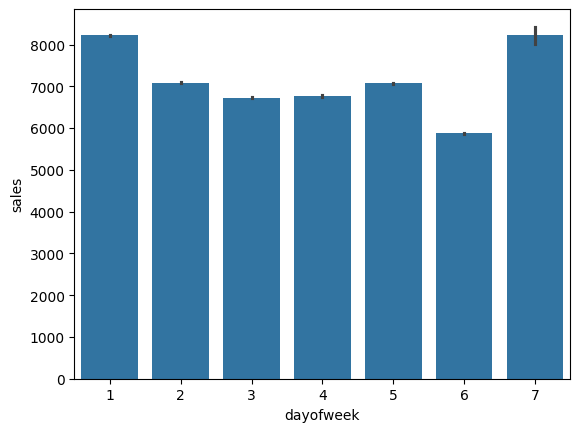

In [39]:
sns.barplot(data=merged_train_df,x="dayofweek",y="sales")


<Axes: xlabel='promo', ylabel='sales'>

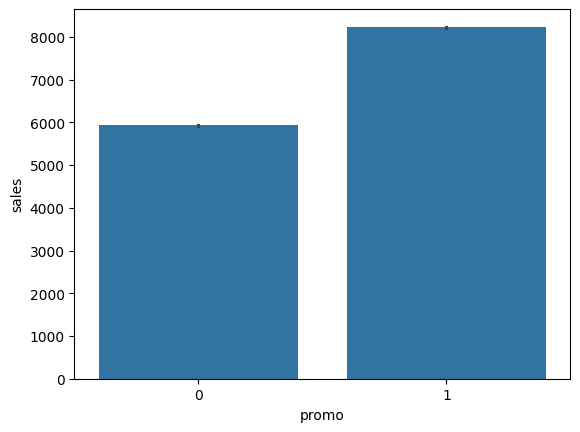

In [40]:
sns.barplot(data=merged_train_df,x="promo",y="sales")

In [41]:
merged_train_df.select_dtypes(include=np.number).corr()["sales"].sort_values(ascending=False)

,sales
sales,1.000000
customers,0.823597
promo,0.368145
promo2sinceweek,0.095311
schoolholiday,0.038617
competitionopensinceyear,0.016101
store,0.007710
promo2sinceyear,-0.034713
competitiondistance,-0.036396
competitionopensincemonth,-0.043489


# Featuring engineering

In [42]:
merged_train_df["day"]=merged_train_df.date.dt.day
merged_train_df["month"]=merged_train_df.date.dt.month
merged_train_df["year"]=merged_train_df.date.dt.year

In [43]:
merged_test_df["day"]=merged_test_df.date.dt.day
merged_test_df["month"]=merged_test_df.date.dt.month
merged_test_df["year"]=merged_test_df.date.dt.year

<Axes: xlabel='year', ylabel='sales'>

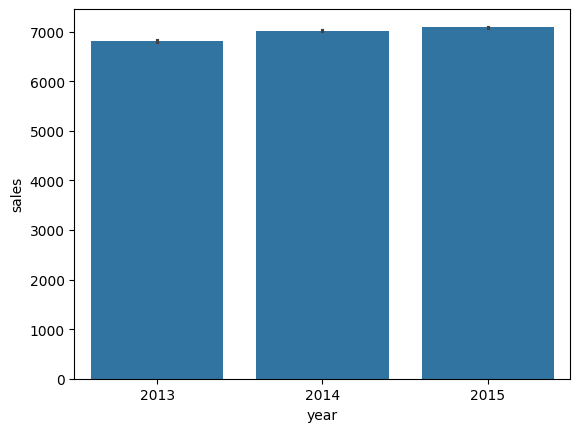

In [44]:
sns.barplot(data=merged_train_df,x="year",y="sales")

<Axes: xlabel='month', ylabel='sales'>

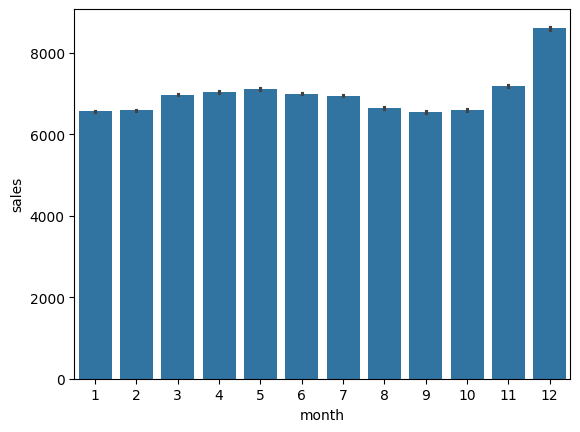

In [45]:
sns.barplot(data=merged_train_df,x="month",y="sales")

# Train/test/validation Split

In [46]:
len(merged_train_df)

844392

In [47]:
x=len(merged_train_df)*0.8
x

675513.6000000001

In [48]:
train_size=int(len(merged_train_df)*0.75)
train_size

633294

In [49]:
sorted_df=merged_train_df.sort_values("date")
train_df,val_df=sorted_df[:train_size],sorted_df[train_size:]

In [50]:
len(train_df),len(val_df)

(633294, 211098)

In [51]:
train_df["date"].min(),train_df["date"].max()

(Timestamp('2013-01-01 00:00:00'), Timestamp('2014-12-10 00:00:00'))

In [52]:
val_df["date"].min(),val_df["date"].max()

(Timestamp('2014-12-10 00:00:00'), Timestamp('2015-07-31 00:00:00'))

In [53]:
train_df.columns

Index(['store', 'dayofweek', 'date', 'sales', 'customers', 'open', 'promo',
       'stateholiday', 'schoolholiday', 'storetype', 'assortment',
       'competitiondistance', 'competitionopensincemonth',
       'competitionopensinceyear', 'promo2', 'promo2sinceweek',
       'promo2sinceyear', 'promointerval', 'day', 'month', 'year'],
      dtype='object')

# Input and Target Column

In [54]:
input_cols=["store","dayofweek","promo","stateholiday","storetype","assortment","year","month","day"]
target_col=["sales"]

In [55]:
inp=train_df.drop(columns="sales")
inp.columns

Index(['store', 'dayofweek', 'date', 'customers', 'open', 'promo',
       'stateholiday', 'schoolholiday', 'storetype', 'assortment',
       'competitiondistance', 'competitionopensincemonth',
       'competitionopensinceyear', 'promo2', 'promo2sinceweek',
       'promo2sinceyear', 'promointerval', 'day', 'month', 'year'],
      dtype='object')

In [56]:
merged_train_df[input_cols].nunique()

,0
store,1115
dayofweek,7
promo,2
stateholiday,4
storetype,4
assortment,3
year,3
month,12
day,31


In [57]:
train_inputs=train_df[input_cols].copy()
train_targets=train_df[target_col].copy()


In [58]:
val_inputs=val_df[input_cols].copy()
val_targets=val_df[target_col].copy()

In [59]:
test_inputs=merged_test_df[input_cols].copy()


In [60]:
numerical_cols=["store","day","month","year"]
categorical_cols=["dayofweek","promo","stateholiday","storetype","assortment"]

In [61]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

In [62]:
imputer=SimpleImputer(strategy="mean").fit(train_inputs[numerical_cols])


In [63]:
train_inputs[numerical_cols]=imputer.transform(train_inputs[numerical_cols])
val_inputs[numerical_cols]=imputer.transform(val_inputs[numerical_cols])
test_inputs[numerical_cols]=imputer.transform(test_inputs[numerical_cols])

In [64]:
from sklearn.preprocessing import MinMaxScaler

In [65]:
scaler=MinMaxScaler().fit(train_inputs[numerical_cols])

In [66]:
train_inputs[numerical_cols]=scaler.transform(train_inputs[numerical_cols])
val_inputs[numerical_cols]=scaler.transform(val_inputs[numerical_cols])
test_inputs[numerical_cols]=scaler.transform(test_inputs[numerical_cols])

In [67]:
from sklearn.preprocessing import OneHotEncoder

In [68]:
encoder=OneHotEncoder(sparse_output=False,handle_unknown="ignore").fit(train_inputs[categorical_cols])

In [69]:
encoded_cols=list(encoder.get_feature_names_out(categorical_cols))

In [70]:
train_inputs[encoded_cols]=encoder.transform(train_inputs[categorical_cols])
val_inputs[encoded_cols]=encoder.transform(val_inputs[categorical_cols])
test_inputs[encoded_cols]=encoder.transform(test_inputs[categorical_cols])

In [71]:
train_inputs

,store,dayofweek,promo,stateholiday,storetype,assortment,year,month,day,dayofweek_1,...,stateholiday_a,stateholiday_b,stateholiday_c,storetype_a,storetype_b,storetype_c,storetype_d,assortment_a,assortment_b,assortment_c
1017190,0.983842,2,0,a,b,b,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1016179,0.075404,2,0,a,b,a,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
1016353,0.231598,2,0,a,b,b,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1016356,0.234291,2,0,a,b,a,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
1016368,0.245063,2,0,a,b,b,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
256632,0.667864,3,0,0,a,a,1.0,1.0,0.3,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
256642,0.677738,3,0,0,a,c,1.0,1.0,0.3,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
256634,0.669659,3,0,0,c,c,1.0,1.0,0.3,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
256633,0.668761,3,0,0,d,c,1.0,1.0,0.3,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0


In [72]:
x_train=train_inputs[numerical_cols+encoded_cols]
x_val=val_inputs[numerical_cols+encoded_cols]
x_test=test_inputs[numerical_cols+encoded_cols]

In [73]:
train_targets.mean()

,0
sales,6873.179642


# Baseline ML Model

In [74]:
def return_mean(inputs):
  return np.full(len(inputs),merged_train_df.sales.mean())

In [75]:
train_preds=return_mean(x_train)

In [76]:
train_preds

array([6955.51429076, 6955.51429076, 6955.51429076, ..., 6955.51429076,
       6955.51429076, 6955.51429076])

In [77]:
from sklearn.metrics import mean_squared_error

In [78]:
np.sqrt(mean_squared_error(train_preds,train_targets))

np.float64(3082.450443277419)

In [79]:
np.sqrt(mean_squared_error(return_mean(x_val),val_targets))

np.float64(3168.6033635047716)

In [80]:
def guess_random(input):
  lo,hi=train_targets.sales.min(),train_targets.sales.max()
  return np.random.random(len(input))*(hi-lo)+lo

In [81]:
train_preds=guess_random(x_train)
train_preds

array([10534.25624397, 28505.5349357 , 30511.52298717, ...,
       21566.09685045, 14405.6865519 , 31049.6944745 ])

In [82]:
np.sqrt(mean_squared_error(train_preds,train_targets))

np.float64(16664.47266956763)

In [83]:
np.sqrt(mean_squared_error(guess_random(x_val),val_targets))

np.float64(16442.917303453505)

In [84]:
from sklearn.linear_model import LinearRegression

In [85]:
linreg=LinearRegression().fit(x_train,train_targets)

In [86]:
x_train.columns

Index(['store', 'day', 'month', 'year', 'dayofweek_1', 'dayofweek_2',
       'dayofweek_3', 'dayofweek_4', 'dayofweek_5', 'dayofweek_6',
       'dayofweek_7', 'promo_0', 'promo_1', 'stateholiday_0', 'stateholiday_a',
       'stateholiday_b', 'stateholiday_c', 'storetype_a', 'storetype_b',
       'storetype_c', 'storetype_d', 'assortment_a', 'assortment_b',
       'assortment_c'],
      dtype='object')

In [87]:
linreg.coef_

array([[ 1.04613988e+02, -1.00014797e+02,  6.50678489e+02,
         1.04413753e+02,  9.88487856e+02, -1.25115344e+02,
        -3.95828726e+02, -3.97660124e+02, -7.18979775e+00,
        -6.37157355e+01,  1.02187074e+00, -1.13867445e+03,
         1.13867445e+03, -1.23115139e+02, -5.62555847e+01,
        -3.90512282e+01,  2.18421952e+02, -1.23677263e+03,
         4.17553271e+03, -1.34703585e+03, -1.59172423e+03,
         9.42626963e+02, -2.61870726e+03,  1.67608030e+03]])

In [88]:
train_preds=linreg.predict(x_train)

In [89]:
np.sqrt(mean_squared_error(train_preds,train_targets))

np.float64(2741.587191916578)

In [90]:
val_pred=linreg.predict(x_val)

In [91]:
np.sqrt(mean_squared_error(val_pred,val_targets))

np.float64(2817.7797940117125)

#Try Different Model

In [92]:

def RMSE (preds,targets):
  answer=np.sqrt(mean_squared_error(preds,targets))
  return answer

In [93]:
def try_model(model):
  # fit the model
  model.fit(x_train,train_targets)

  # generate prediction
  train_preds=model.predict(x_train)
  val_preds=model.predict(x_val)

  # compute RMSE
  train_rmse=RMSE(train_preds,train_targets)
  val_rmse=RMSE(val_preds,val_targets)
  return train_rmse,val_rmse


Linear model

In [94]:
from sklearn.linear_model import LinearRegression,Ridge,Lasso,ElasticNet,SGDRegressor

In [95]:
linear=[LinearRegression,Ridge,Lasso,ElasticNet,SGDRegressor]

In [96]:
import pandas as pd

# List of the classes (not instances yet)
linear_algorithms = [LinearRegression, Ridge, Lasso, ElasticNet, SGDRegressor]

def run_linear_comparison():
    results = []

    for algo in linear_algorithms:
        # 1. Instantiate the model: algo()
        model_instance = algo()

        # 2. Run your try_model function
        train_rmse, val_rmse = try_model(model_instance)

        # 3. Save the results with the model name
        results.append({
            'Model': algo.__name__,
            'Train RMSE': train_rmse,
            'Val RMSE': val_rmse
        })

    # 4. Convert to DataFrame for easy viewing
    return pd.DataFrame(results)

# Execute and see the table
comparison_df = run_linear_comparison()
print(comparison_df)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


              Model   Train RMSE     Val RMSE
0  LinearRegression  2741.587192  2817.779794
1             Ridge  2741.587195  2817.778467
2             Lasso  2741.714390  2817.947292
3        ElasticNet  2879.043210  2972.665886
4      SGDRegressor  2741.990987  2815.835163


In [97]:
def linear_model ():
  result=[]
  for x in linear:
    x_rsme,val_rsme=try_model(x())
    result.append({
        "model":x.__name__,
        "train_rmse":x_rsme,
        "val_rmse":val_rsme
    })
  return pd.DataFrame(result)


linear_model()

In [98]:
model=LinearRegression()
try_model(model)

(np.float64(2741.587191916578), np.float64(2817.7797940117125))

Non linear model

In [99]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor,GradientBoostingRegressor
from xgboost import XGBRegressor

In [100]:
non_linear=[DecisionTreeRegressor,RandomForestRegressor,GradientBoostingRegressor,XGBRegressor]

In [101]:
def non_linear_model():
  result=[]
  for i in non_linear:
    if i.__name__=="DecisionTreeRegressor":
      model=i(max_depth=4)
    elif i.__name__=="RandomForestRegressor":
      model=i(n_estimators=20,n_jobs=-1)
    elif i.__name__=="GradientBoostingRegressor":
      model=i(n_estimators=20)
    elif i.__name__=="XGBRegressor":
      model=i(n_estimators=20,n_jobs=-1)
    train_rsme,test_rsme=try_model(model)
    result.append({
        "model":i.__name__,
        "train_rmse":train_rsme,
        "test_rmse":test_rsme
    })
  return pd.DataFrame(result)

In [102]:
non_linear_model()

/usr/local/lib/python3.13/dist-packages/sklearn/base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_gb.py:672: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)  # TODO: Is this still required?


,model,train_rmse,test_rmse
0,DecisionTreeRegressor,2706.946883,2802.745383
1,RandomForestRegressor,514.448252,1394.956199
2,GradientBoostingRegressor,2697.348803,2787.226705
3,XGBRegressor,2255.268498,2419.825614


# K-fold Cross Validation

In [103]:
from sklearn.model_selection import cross_val_score

Grid Search with and without CV

In [ ]:
model=RandomForestRegressor(max_depth=5,n_estimators=15, n_jobs=-1)
scores=cross_val_score(model,x_train,train_targets,cv=3,scoring="neg_root_mean_squared_error")
rmse_score=-scores

/usr/local/lib/python3.13/dist-packages/sklearn/base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


In [ ]:
print(f"RMSE for each fold: {rmse_score}")
print(f"Average RMSE: {np.mean(rmse_score):.2f}")
print(f"Standard Deviation: {np.std(rmse_score):.2f}")

# Grid search

In [ ]:
from sklearn.model_selection import GridSearchCV,RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier

In [ ]:
model=RandomForestClassifier(n_jobs=3,random_state=42)

In [ ]:
param_grids={
    'max_depth':[3,4],
    "n_estimators":[25,39]
}

In [ ]:
grid_search=GridSearchCV(
    estimator=model,
    param_grid=param_grids,cv=3,
    scoring="neg_root_mean_squared_error")

In [ ]:
#result=grid_search.fit(x_train,train_targets)

# Pipeline combined with Grid search

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [ ]:
pipeline=Pipeline([
    ("imputer",SimpleImputer()),
    ("scaler",MinMaxScaler()),
    ("model",RandomForestRegressor())
])

In [ ]:
param_grid={
    #step_name__parameter_name
    "imputer__strategy":["mean","most_frequent"],
    "scaler":[MinMaxScaler(),StandardScaler()],# You can even swap entire transformers!
    #
    "model__max_depth":[3,4],
    "model__min_samples_split":[2,5]
}

In [ ]:
gridsearch=GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=2,
    n_jobs=2,
    scoring="neg_root_mean_squared_error",
    verbose=1
)

In [ ]:
# 4. Fit GridSearch on Training Data
gridsearch.fit(x_train,train_targets)

# 5. Review Best Parameters & Score
print("Best Parameters Found:")
print(gridsearch.best_params_)
print(f"\nBest Cross-Validation in rmse: {-gridsearch.best_score_:.4f}")

# 6. Evaluate Best Model directly on Validation Data
# 'gridsearch' automatically behaves as the best pipeline model!
best_pipeline = gridsearch.best_estimator_
val_score = best_pipeline.score(x_val, val_targets)
print(f"Validation R^2 with Best Model: {val_score:.4f}")

Fitting 2 folds for each of 16 candidates, totalling 32 fits


/usr/local/lib/python3.13/dist-packages/sklearn/base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


Best Parameters Found:
{'imputer__strategy': 'most_frequent', 'model__max_depth': 4, 'model__min_samples_split': 2, 'scaler': StandardScaler()}

Best Cross-Validation in rmse: 2910.4723
Validation R^2 with Best Model: 0.2141


In [ ]:

def train_and_evaluation():
  model=LinearRegression().fit(x_tr,y_target)
  pred_tr=model.predict(x_tr)
  pred_val=model.predict(x_val)
  score_tr=np.sqrt(mean_squared_error(pred_tr,y_target))
  score_val=np.sqrt(mean_squared_error(pred_val,y_val))
  return model,score_tr,score_val

In [ ]:
#Using a single kfold of 5
models=[]
mod=[]
from sklearn.model_selection import KFold
kf=KFold(n_splits=3)
kf.split(x_train)
print(kf.split(x_train))
for train_idx,val_idx in kf.split(x_train):
  x_tr,x_val=x_train.iloc[train_idx],x_train.iloc[val_idx]
  y_target,y_val=train_targets.iloc[train_idx],train_targets.iloc[val_idx]
  model,train_score,val_score=train_and_evaluation()
  models.append({
      "train_score":train_score,
      "val_score":val_score
  })
  mod.append(model)


<generator object _BaseKFold.split at 0x7c76b978e8a0>


In [ ]:
kfold_results=pd.DataFrame(models)
kfold_results

In [ ]:
mod

In [ ]:
def average(models,inputs,like_output) :
  collector=[]
  for model in models:
    pred=model.predict(inputs)
    score=np.sqrt(mean_squared_error(like_output,pred))
    collector.append(score)
  x=np.array(collector)
  return np.mean(x)

In [ ]:
average(mod,x_train,train_targets)

# Submission File

In [ ]:
best_pipeline

In [ ]:
test_pred=best_pipeline.predict(x_test)

In [ ]:
x_test.columns

In [ ]:
len(test_pred)

In [ ]:
merged_test_df

In [ ]:
submission_df=pd.read_csv(path + '/sample_submission.csv',low_memory=False)

In [ ]:
submission_df

In [ ]:
submission_df["Sales"]=test_pred * merged_test_df["open"].fillna(1)

In [ ]:
merged_test_df["open"]

In [ ]:
submission_df

In [ ]:
submission_df.to_csv("submission_df",index=None)

In [ ]:
# Base class demonstrating Encapsulation & Abstraction
class Vehicle:
    def __init__(self, brand: str):
        self.brand = brand
        self._speed = 0  # Internal state protected from direct external tampering

    def accelerate(self, amount: int):
        self._speed += amount
        print(f"{self.brand} is traveling at {self._speed} km/h")

    def move(self):
        raise NotImplementedError("Subclasses must implement move()")

# Subclasses demonstrating Inheritance & Polymorphism
class Car(Vehicle):
    def move(self):
        print(f"{self.brand} drives on four wheels.")

class Boat(Vehicle):
    def move(self):
        print(f"{self.brand} sails across the water.")

# Polymorphic behavior in practice
fleet = [Car("Tesla"), Boat("Sea Ray")]
for vehicle in fleet:
    vehicle.move()  # Same method call, class-specific outcome